In [ ]:
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

In [ ]:
# Load MNIST dataset
mnist = fetch_openml('mnist_784', version=1, as_frame=False)
X = mnist.data
y = mnist.target.astype(int)
print("Dataset shape:", X.shape)

Dataset shape: (70000, 784)


In [ ]:
print(X[:5])

[[0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]]


In [ ]:
print(X[:5, :10])

[[0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0]]


In [ ]:
# Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [ ]:
# Standardization
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [ ]:
#simple perception
from sklearn.linear_model import Perceptron
perceptron = Perceptron()
perceptron.fit(X_train, y_train)
y_pred = perceptron.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", accuracy)

Accuracy: 0.8759285714285714


In [ ]:
#MLP
mlp = MLPClassifier(hidden_layer_sizes=(10000,),max_iter=50,random_state=42)
mlp.fit(X_train, y_train)

/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:698: UserWarning: Training interrupted by user.
  warnings.warn("Training interrupted by user.")


MLPClassifier(hidden_layer_sizes=(10000,), max_iter=50, random_state=42)

In [ ]:
#Predcitions
y_pred_mlp = mlp.predict(X_test)

# Accuracy
mlp_accuracy = accuracy_score(y_test, y_pred_mlp)
print("MLP Accuracy:", mlp_accuracy)


MLP Accuracy: 0.8932857142857142


In [ ]:
# 7. Comparison
mlp_accuracy = accuracy_score(y_test, y_pred_mlp)
print("\nPerformance Comparison")
print("Perceptron Accuracy : {:.2f}%".format(accuracy * 100))
print("MLP Accuracy : {:.2f}%".format(mlp_accuracy * 100))


Performance Comparison
Perceptron Accuracy : 87.59%
MLP Accuracy : 89.33%


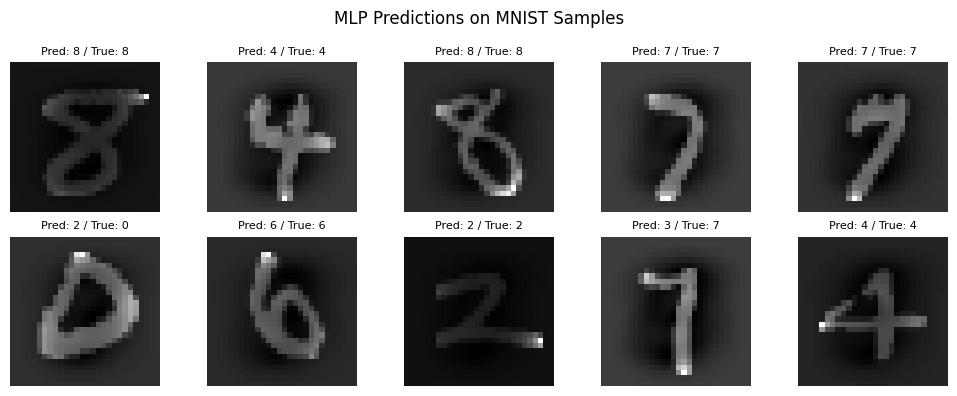

In [ ]:
#8.Visualization
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 4))
for i in range(10):
    plt.subplot(2, 5, i+1)
    plt.imshow(X_test[i].reshape(28, 28), cmap='gray')
    plt.title(f"Pred: {y_pred_mlp[i]} / True: {y_test[i]}", fontsize=8)
    plt.axis('off')

plt.suptitle("MLP Predictions on MNIST Samples")
plt.tight_layout()
plt.show()